## 1. Preprocessing

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(r"/content/student_exam_performance.csv")

print("Dataset shape:", df.shape)  # Basic dataset check

duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

print("Number of duplicated student IDs:", df["student_id"].duplicated().sum())
print("Number of unique student IDs:", df["student_id"].nunique())

# Check the target before the split
print("\nMissing target values:")
print(df["pass_status"].isna().sum())

print("\nTarget classes:")
print(df["pass_status"].unique())

print("\nTarget distribution:")
print(df["pass_status"].value_counts())

print("\nTarget distribution (%):")
print(df["pass_status"].value_counts(normalize=True) * 100)

# Clean target values before encoding
df["pass_status"] = (
    df["pass_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("\nCleaned target classes:")
print(df["pass_status"].value_counts(dropna=False))

target_mapping = {
    "pass": 0,
    "fail": 1
}

df["pass_status"] = df["pass_status"].map(target_mapping)

print("\nEncoded target distribution:")
print(df["pass_status"].value_counts(dropna=False))

print("\nMissing values after target encoding:")
print(df["pass_status"].isna().sum())

# Remove the target, ID, and outcome-related columns
target_column = "pass_status"
leakage_columns = [
    "student_id",
    "exam_score",
    "performance_grade",
    "performance_level",
    "questions_attempted",
    "questions_correct"
]
X = df.drop(columns=[target_column] + leakage_columns)
y = df[target_column]

# Clean categorical values
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns

for column in categorical_columns:
    X[column] = X[column].astype("string").str.strip().str.lower()

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns

print("\nNumerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

# Split before imputation to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

# Check important numerical ranges for possible invalid values
columns_to_check = ["age", "previous_exam_score", "previous_gpa", "attendance_percentage", "assignment_completion_rate", "study_hours_per_day", "self_study_hours", "online_course_hours", "physical_activity_hours", "daily_screen_time"]

print("\nRange checks:")

for column in columns_to_check:
    if column in X_train.columns:
        print(column, "min =", X_train[column].min(), "max =", X_train[column].max())

# Fill numerical missing values using the training median
for column in numerical_columns:
    median_value = X_train[column].median()
    X_train[column] = X_train[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

# Fill categorical missing values using the training mode
for column in categorical_columns:
    mode_value = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(mode_value)
    X_test[column] = X_test[column].fillna(mode_value)

print("\nMissing values after imputation:")
print("Training:", X_train.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())

# Convert categorical variables into 0/1 columns
X_train = pd.get_dummies(X_train, columns=categorical_columns, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_columns, drop_first=True, dtype=int)

# Make sure train and test have exactly the same features
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("\nShape after one-hot encoding:")
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

# Keep unscaled data for tree-based models
# Create scaled copies for models that are sensitive to feature scale
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Standardize only the original numerical variables
scaler = StandardScaler()

scaler_columns = [column for column in numerical_columns if column in X_train.columns]

X_train_scaled[scaler_columns] = scaler.fit_transform(X_train[scaler_columns])
X_test_scaled[scaler_columns] = scaler.transform(X_test[scaler_columns])

# Final checks
print("\nPre-processing completed successfully.")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nScaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

print("\nTarget variable distribution:")
print(y.value_counts())

print("\nMissing values in training data:")
print(X_train.isnull().sum().sum())

print("Missing values in testing data:")
print(X_test.isnull().sum().sum())

print("\nMissing values in scaled training data:")
print(X_train_scaled.isnull().sum().sum())

print("Missing values in scaled testing data:")
print(X_test_scaled.isnull().sum().sum())

print("\nFinal number of features:", X_train.shape[1])

Dataset shape: (100000, 44)
Number of duplicate rows: 0
Number of duplicated student IDs: 0
Number of unique student IDs: 100000

Missing target values:
0

Target classes:
['Pass' 'Fail']

Target distribution:
pass_status
Pass    77389
Fail    22611
Name: count, dtype: int64

Target distribution (%):
pass_status
Pass    77.389
Fail    22.611
Name: proportion, dtype: float64

Cleaned target classes:
pass_status
pass    77389
fail    22611
Name: count, dtype: Int64

Encoded target distribution:
pass_status
0    77389
1    22611
Name: count, dtype: int64

Missing values after target encoding:
0

Numerical columns:
['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'practice_tests_completed', 'sleep_hours', 'daily_screen_time', 'physical_activity_hours', 'stress_level', 'internet_access', 'online_course_hours', 'exam_preparation_days', 'time_management_s

## 2. Modeling Imports

In [ ]:
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {"Accuracy":"accuracy", "Precision_Fail":"precision", "Recall_Fail":"recall",
           "F1_Fail":"f1", "ROC_AUC":"roc_auc", "PR_AUC":"average_precision"}

## 3. Cross-Validation Function

In [ ]:
def get_cv_results(model_name, model, X_used):
    start = time.time()
    scores = cross_validate(model, X_used, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    return {"Model":model_name,
            "CV_Accuracy":scores["test_Accuracy"].mean(),
            "CV_Precision_Fail":scores["test_Precision_Fail"].mean(),
            "CV_Recall_Fail":scores["test_Recall_Fail"].mean(),
            "CV_F1_Fail":scores["test_F1_Fail"].mean(),
            "CV_ROC_AUC":scores["test_ROC_AUC"].mean(),
            "CV_PR_AUC":scores["test_PR_AUC"].mean(),
            "CV_Time_Seconds":time.time()-start}

## 4. Initial Model Comparison

In [ ]:
dummy_model = DummyClassifier(strategy="most_frequent", random_state=42)
logistic_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
tree_model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20,
                                    class_weight="balanced", random_state=42)

cv_results = [
    get_cv_results("Dummy Classifier", dummy_model, X_train),
    get_cv_results("Logistic Regression", logistic_model, X_train_scaled),
    get_cv_results("Decision Tree", tree_model, X_train)
]
cv_results_df = pd.DataFrame(cv_results).sort_values(
    by=["CV_F1_Fail", "CV_Recall_Fail", "CV_PR_AUC"], ascending=False)
display(cv_results_df.round(4))

,Model,CV_Accuracy,CV_Precision_Fail,CV_Recall_Fail,CV_F1_Fail,CV_ROC_AUC,CV_PR_AUC,CV_Time_Seconds
1,Logistic Regression,0.7995,0.5372,0.8171,0.6482,0.8930,0.7260,0.9666
2,Decision Tree,0.7447,0.4642,0.8002,0.5867,0.8419,0.6007,1.6961
0,Dummy Classifier,0.7739,0.0000,0.0000,0.0000,0.5000,0.2261,0.2780


## 5. Limited Tuning: Logistic Regression

In [ ]:
logistic_search = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    {"C":[0.1, 1, 10]}, scoring="f1", cv=cv, n_jobs=-1)
logistic_search.fit(X_train_scaled, y_train)
best_logistic = logistic_search.best_estimator_
print("Best parameters:", logistic_search.best_params_)
print("Best CV F1:", logistic_search.best_score_)

Best parameters: {'C': 0.1}
Best CV F1: 0.6483101828763246


## 6. Limited Tuning: Decision Tree

In [ ]:
tree_search = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"max_depth":[4, 6, 8, 12], "min_samples_leaf":[10, 20, 50]},
    scoring="f1", cv=cv, n_jobs=-1)
tree_search.fit(X_train, y_train)
best_tree = tree_search.best_estimator_
print("Best parameters:", tree_search.best_params_)
print("Best CV F1:", tree_search.best_score_)

Best parameters: {'max_depth': 12, 'min_samples_leaf': 50}
Best CV F1: 0.6060992096521695


## 7. Final Test Evaluation Function

In [ ]:
def evaluate_on_test(model_name, model, X_train_used, X_test_used):
    start = time.time()
    model.fit(X_train_used, y_train)
    training_time = time.time() - start
    y_pred = model.predict(X_test_used)
    y_prob = model.predict_proba(X_test_used)[:, 1]
    result = {"Model":model_name, "Accuracy":accuracy_score(y_test,y_pred),
              "Precision_Fail":precision_score(y_test,y_pred,zero_division=0),
              "Recall_Fail":recall_score(y_test,y_pred,zero_division=0),
              "F1_Fail":f1_score(y_test,y_pred,zero_division=0),
              "ROC_AUC":roc_auc_score(y_test,y_prob),
              "PR_AUC":average_precision_score(y_test,y_prob),
              "Training_Time_Seconds":training_time}
    print("\n" + model_name)
    print(classification_report(y_test, y_pred, target_names=["Pass","Fail"], zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Pass","Fail"], yticklabels=["Pass","Fail"])
    plt.title("Confusion Matrix - " + model_name)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.show()
    return result, y_pred, y_prob

## 8. Evaluate Person 1 Models


Dummy Classifier
              precision    recall  f1-score   support

        Pass       0.77      1.00      0.87     15478
        Fail       0.00      0.00      0.00      4522

    accuracy                           0.77     20000
   macro avg       0.39      0.50      0.44     20000
weighted avg       0.60      0.77      0.68     20000



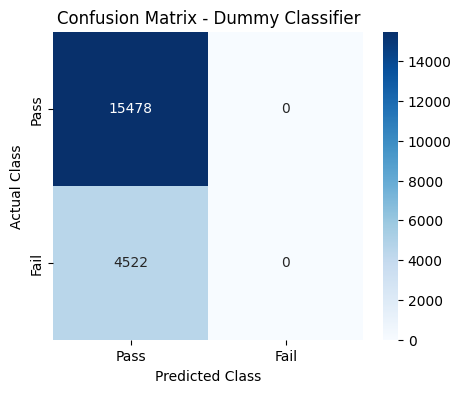


Tuned Logistic Regression
              precision    recall  f1-score   support

        Pass       0.94      0.79      0.86     15478
        Fail       0.53      0.82      0.65      4522

    accuracy                           0.80     20000
   macro avg       0.74      0.81      0.75     20000
weighted avg       0.85      0.80      0.81     20000



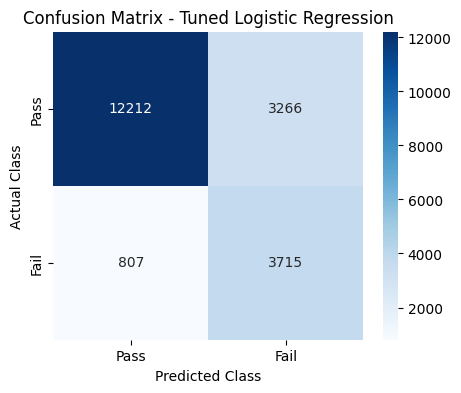


Tuned Decision Tree
              precision    recall  f1-score   support

        Pass       0.93      0.76      0.84     15478
        Fail       0.49      0.79      0.61      4522

    accuracy                           0.77     20000
   macro avg       0.71      0.78      0.72     20000
weighted avg       0.83      0.77      0.78     20000



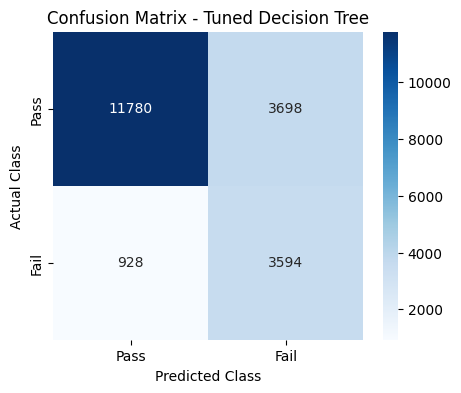

,Model,Accuracy,Precision_Fail,Recall_Fail,F1_Fail,ROC_AUC,PR_AUC,Training_Time_Seconds
1,Tuned Logistic Regression,0.7964,0.5322,0.8215,0.6459,0.8900,0.7202,0.8047
2,Tuned Decision Tree,0.7687,0.4929,0.7948,0.6084,0.8561,0.6474,2.1784
0,Dummy Classifier,0.7739,0.0000,0.0000,0.0000,0.5000,0.2261,0.0059


In [ ]:
test_results = []
result, dummy_pred, dummy_prob = evaluate_on_test("Dummy Classifier", dummy_model, X_train, X_test)
test_results.append(result)
result, logistic_pred, logistic_prob = evaluate_on_test("Tuned Logistic Regression", best_logistic, X_train_scaled, X_test_scaled)
test_results.append(result)
result, tree_pred, tree_prob = evaluate_on_test("Tuned Decision Tree", best_tree, X_train, X_test)
test_results.append(result)

person1_results = pd.DataFrame(test_results).sort_values(
    by=["F1_Fail", "Recall_Fail", "PR_AUC"], ascending=False)
display(person1_results.round(4))

## 9. Interpretation and Save Results

In [ ]:

logistic_coefficients = pd.DataFrame({"Feature":X_train_scaled.columns,
                                      "Coefficient":best_logistic.coef_[0]})
logistic_coefficients["Absolute_Coefficient"] = logistic_coefficients["Coefficient"].abs()
display(logistic_coefficients.sort_values("Absolute_Coefficient", ascending=False).head(15))

person1_results.to_csv("person1_model_results.csv", index=False)

,Feature,Coefficient,Absolute_Coefficient
58,exam_difficulty_hard,2.782646,2.782646
1,previous_exam_score,-1.448647,1.448647
59,exam_difficulty_medium,1.407977,1.407977
5,study_hours_per_day,-0.943437,0.943437
16,exam_preparation_days,-0.661229,0.661229
9,practice_tests_completed,-0.636042,0.636042
3,attendance_percentage,-0.412472,0.412472
10,sleep_hours,-0.379823,0.379823
13,stress_level,0.333963,0.333963
17,time_management_score,-0.232761,0.232761
